# 01. PaySim 데이터 점검과 시간순 분할

**목적:** 공개 합성 금융거래 원본 전체를 PySpark로 점검하고, 같은 `step`을 유지하는
Train / Validation / Test 데이터셋을 Parquet으로 저장한다.

- 데이터: [Kaggle · ealaxi/paysim1](https://www.kaggle.com/datasets/ealaxi/paysim1)
- 목표 비율: 거래 건수 기준 약 **60% / 20% / 20%** (시간순, 무작위 섞기 없음)
- 정답은 분포 감사에만 사용하고, 분할 경계 선택에는 사용하지 않는다.
- 이 노트북은 연구용 분할 데이터를 만듭니다. 저장된 원본 컬럼에는 정답이 있으므로
  모델 특징과 Agent 입력은 별도 허용 목록으로 구성해야 한다.
- 동일 `step` 내부의 실제 거래 순서는 알 수 없다. 향후 이력 특징은 반드시
  `history.step < current.step` 조건을 사용한다.

프로젝트의 `.venv` 커널에서 **위에서 아래로 모두 실행**한다.
전체 CSV를 Pandas에 올리지 않고 Spark로 집계하며, 작은 집계표만 Pandas로 변환한다.


SPARK_WORKERS = 2는 local-cluster worker 수를 뜻한다. 각 worker는 1 core와 1 GiB 자원을 광고하고, executor heap은 768 MiB로 제한한다. 이 값은 사용 가능한 메모리를 고려한 시연 설정으로 사용한다.

In [1]:
import csv
import hashlib
import json
import os
import platform
import shutil
import subprocess
import sys
import time
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML, display
from pyspark import StorageLevel
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import types as T

ROOT = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "pyproject.toml").is_file() and (p / "src/fds_agent").is_dir()
    ),
    None,
)
assert ROOT is not None, "프로젝트 루트 또는 notebooks 폴더에서 실행한다."
RAW = ROOT / "data/raw"
# CSV가 여러 개이면 사용할 파일명을 지정한다.
CSV_NAME = None
TRAIN_FRACTION = 0.60
VALIDATION_FRACTION = 0.20
SPARK_WORKERS = 2
WORKER_CORES = 1
WORKER_MEMORY_MB = 1024
EXECUTOR_MEMORY = "768m"
DRIVER_MEMORY = "1g"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:8]
REPORT_DIR = ROOT / "artifacts/reports" / RUN_ID
OUTPUT_DIR = ROOT / "data/processed/paysim_time_split" / RUN_ID
REPORT_DIR.mkdir(parents=True, exist_ok=False)
started = time.perf_counter()
print("Python:", sys.version.split()[0], "| 실행 파일:", sys.executable)
print("프로젝트:", ROOT)
print("실행 ID:", RUN_ID)

Python: 3.11.14 | 실행 파일: /Users/yueun/Desktop/FDS-AI-Agent/.venv/bin/python
프로젝트: /Users/yueun/Desktop/FDS-AI-Agent
실행 ID: 20261117T085920Z-cec632a0


## 1. 원본 준비와 출처 기록

기존 CSV가 있으면 그대로 사용한다. CSV가 없으면 `data/raw/paysim.zip` 또는
다운로드가 끝난 `paysim.zip.part`를 검사해 CSV 하나만 추출한다.
손상된 ZIP, CSV 여러 개, 예상과 다른 컬럼은 조용히 넘어가지 않고 중단한다.

원본은 수정하지 않으며 SHA-256과 파일 크기를 기록한다. 파일 해시는 이번에 사용한
원본을 식별하기 위한 것으로, 게시자가 제공한 체크섬과 대조한 인증은 아닙니다.


In [2]:
RAW.mkdir(parents=True, exist_ok=True)
candidates = sorted(RAW.glob("*.csv"))
if CSV_NAME:
    csv_path = RAW / CSV_NAME
    assert csv_path.is_file(), f"CSV가 없다: {csv_path}"
elif len(candidates) == 1:
    csv_path = candidates[0]
elif len(candidates) > 1:
    raise ValueError("CSV가 여러 개이다. CSV_NAME을 지정한다.")
else:
    archive = RAW / "paysim.zip"
    partial = RAW / "paysim.zip.part"
    if not archive.exists() and partial.exists():
        assert zipfile.is_zipfile(partial), "다운로드가 완료된 ZIP이 아닙니다."
        with zipfile.ZipFile(partial) as zf:
            assert zf.testzip() is None, "ZIP 무결성 검사 실패"
        partial.rename(archive)
    if not archive.exists():
        raise FileNotFoundError(
            "Kaggle ealaxi/paysim1에서 받은 CSV 또는 paysim.zip을 data/raw/에 넣는다."
        )
    with zipfile.ZipFile(archive) as zf:
        assert zf.testzip() is None, "ZIP 무결성 검사 실패"
        members = [m for m in zf.infolist() if m.filename.lower().endswith(".csv")]
        assert len(members) == 1, "ZIP 안에 CSV가 정확히 하나 있어야 한다."
        member = members[0]
        assert shutil.disk_usage(RAW).free > member.file_size * 2, "추출 공간 부족"
        csv_path = RAW / Path(member.filename).name
        temporary_csv = csv_path.with_suffix(".csv.extracting")
        with zf.open(member) as source, temporary_csv.open("wb") as target:
            shutil.copyfileobj(source, target, length=1024 * 1024)
        temporary_csv.rename(csv_path)

EXPECTED_COLUMNS = [
    "step",
    "type",
    "amount",
    "nameOrig",
    "oldbalanceOrg",
    "newbalanceOrig",
    "nameDest",
    "oldbalanceDest",
    "newbalanceDest",
    "isFraud",
    "isFlaggedFraud",
]
with csv_path.open(newline="", encoding="utf-8-sig") as handle:
    assert next(csv.reader(handle)) == EXPECTED_COLUMNS, "예상과 다른 CSV 컬럼이다."
sha256 = hashlib.sha256()
with csv_path.open("rb") as handle:
    for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b""):
        sha256.update(chunk)
source_info = {
    "dataset": "ealaxi/paysim1",
    "source_url": "https://www.kaggle.com/datasets/ealaxi/paysim1",
    "download_url": "https://www.kaggle.com/api/v1/datasets/download/ealaxi/paysim1",
    "csv": str(csv_path.relative_to(ROOT)),
    "bytes": csv_path.stat().st_size,
    "sha256": sha256.hexdigest(),
}
print(json.dumps(source_info, indent=2, ensure_ascii=False))

{
  "dataset": "ealaxi/paysim1",
  "source_url": "https://www.kaggle.com/datasets/ealaxi/paysim1",
  "download_url": "https://www.kaggle.com/api/v1/datasets/download/ealaxi/paysim1",
  "csv": "data/raw/PS_20174392719_1491204439457_log.csv",
  "bytes": 493534783,
  "sha256": "16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b"
}


## 2. Spark 로딩과 품질 검사

명시적 스키마와 `FAILFAST`로 읽어 형식 오류를 감지한다. 결측, NaN/무한대,
음수 금액·잔액, 유효하지 않은 레이블·거래 유형은 검사 실패로 처리한다.
잔액 `0`은 결측으로 간주하지 않는다. 이번 단계에서는 임의의 행 삭제나 중복 제거를 하지 않는다.


Spark는 `local-cluster[2,1,1024]` 모드로 실행한다. 한 대의 컴퓨터 안에서 worker 2개와 executor JVM을 띄워 Spark의 task 배분·shuffle 과정을 관찰한다. 실제 여러 서버로 구성한 외부 클러스터는 아니며, Spark UI와 이벤트 로그를 보고서에 남긴다.

In [3]:
if sys.platform == "darwin" and not os.environ.get("JAVA_HOME"):
    os.environ["JAVA_HOME"] = subprocess.check_output(
        ["/usr/libexec/java_home", "-v", "17"], text=True
    ).strip()
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")
EVENT_LOG_DIR = REPORT_DIR / "spark-events"
EVENT_LOG_DIR.mkdir(parents=True, exist_ok=True)
spark = (
    SparkSession.builder.master(f"local-cluster[{SPARK_WORKERS},{WORKER_CORES},{WORKER_MEMORY_MB}]")
    .appName("FDS-PaySim-EDA-Split")
    .config("spark.driver.memory", DRIVER_MEMORY)
    .config("spark.executor.memory", EXECUTOR_MEMORY)
    .config("spark.executor.cores", str(WORKER_CORES))
    .config("spark.cores.max", str(SPARK_WORKERS * WORKER_CORES))
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.ui.enabled", "true")
    .config("spark.ui.port", "4040")
    .config("spark.ui.retainedJobs", "200")
    .config("spark.ui.retainedStages", "500")
    .config("spark.eventLog.enabled", "true")
    .config("spark.eventLog.dir", EVENT_LOG_DIR.as_uri())
    .config("spark.driver.bindAddress", "127.0.0.1")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark:", spark.version)
print("Spark master:", spark.sparkContext.master)
print("Spark UI:", spark.sparkContext.uiWebUrl)
print("Spark UI 작업·stage 기록을 실행 보고서에 저장한다.")

numeric_columns = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
integer_columns = ["step", "isFraud", "isFlaggedFraud"]
schema = T.StructType(
    [
        T.StructField(
            name,
            T.IntegerType()
            if name in integer_columns
            else T.DoubleType()
            if name in numeric_columns
            else T.StringType(),
            True,
        )
        for name in EXPECTED_COLUMNS
    ]
)
df = (
    spark.read.option("header", True)
    .option("mode", "FAILFAST")
    .option("enforceSchema", False)
    .schema(schema)
    .csv(str(csv_path))
    .persist(StorageLevel.MEMORY_AND_DISK)
)
quality = (
    df.agg(
        F.count("*").alias("rows"),
        *[
            F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(f"null_{c}")
            for c in EXPECTED_COLUMNS
        ],
        *[
            F.sum(F.when(F.isnan(c) | (F.abs(F.col(c)) == float("inf")), 1).otherwise(0)).alias(
                f"nonfinite_{c}"
            )
            for c in numeric_columns
        ],
        *[
            F.sum(F.when(F.col(c) < 0, 1).otherwise(0)).alias(f"negative_{c}")
            for c in numeric_columns
        ],
        F.sum(F.when(F.col("step") < 1, 1).otherwise(0)).alias("invalid_step"),
        *[
            F.sum(F.when(~F.col(c).isin(0, 1), 1).otherwise(0)).alias(f"invalid_{c}")
            for c in ["isFraud", "isFlaggedFraud"]
        ],
        F.sum(
            F.when(
                ~F.col("type").isin("PAYMENT", "TRANSFER", "CASH_OUT", "DEBIT", "CASH_IN"), 1
            ).otherwise(0)
        ).alias("invalid_type"),
        *[
            F.sum(F.when(F.trim(F.col(c)) == "", 1).otherwise(0)).alias(f"empty_{c}")
            for c in ["nameOrig", "nameDest"]
        ],
    )
    .first()
    .asDict()
)
assert quality["rows"] > 0, "원본 데이터가 비어 있다."
issues = {key: value for key, value in quality.items() if key != "rows" and value != 0}
display(pd.DataFrame([quality]).T.rename(columns={0: "count"}))
assert not issues, f"품질 검사 실패: {issues}"
print(f"품질 검사 통과: {quality['rows']:,}건")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/17 17:59:22 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


ERROR:root:Exception while sending command.
Traceback (most recent call last):
  File "/Users/yueun/Desktop/FDS-AI-Agent/.venv/lib/python3.11/site-packages/py4j/clientserver.py", line 535, in send_command
    answer = smart_decode(self.stream.readline()[:-1])
                          ^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: reentrant call inside <_io.BufferedReader name=89>

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/Users/yueun/Desktop/FDS-AI-Agent/.venv/lib/python3.11/site-packages/py4j/java_gateway.py", line 1038, in send_command
    response = connection.send_command(command)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/yueun/Desktop/FDS-AI-Agent/.venv/lib/python3.11/site-packages/py4j/clientserver.py", line 566, in send_command
    raise Py4JNetworkError(
py4j.protocol.Py4JNetworkError: Error while sending or receiving


ERROR:root:Exception while sending command.
Traceback (most recent call last):
  File "/Users/yueun/Desktop/FDS-AI-Agent/.venv/lib/python3.11/site-packages/py4j/clientserver.py", line 535, in send_command
    answer = smart_decode(self.stream.readline()[:-1])
                          ^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/homebrew/Cellar/python@3.11/3.11.14_1/Frameworks/Python.framework/Versions/3.11/lib/python3.11/socket.py", line 718, in readinto
    return self._sock.recv_into(b)
           ^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/yueun/Desktop/FDS-AI-Agent/.venv/lib/python3.11/site-packages/pyspark/core/context.py", line 389, in signal_handler
    self.cancelAllJobs()
  File "/Users/yueun/Desktop/FDS-AI-Agent/.venv/lib/python3.11/site-packages/pyspark/core/context.py", line 2487, in cancelAllJobs
    self._jsc.sc().cancelAllJobs()
    ^^^^^^^^^^^^^^
  File "/Users/yueun/Desktop/FDS-AI-Agent/.venv/lib/python3.11/site-packages/py4j/java_gateway.py", line 1362, in __call__
    return_valu

26/11/17 17:59:23 WARN Master: Got status update for unknown executor app-20261117175922-0000/1
26/11/17 17:59:23 ERROR Worker: Failed to launch executor app-20261117175922-0000/2 for FDS-PaySim-EDA-Split.
java.lang.IllegalStateException: Shutdown hooks cannot be modified during shutdown.
	at org.apache.spark.util.SparkShutdownHookManager.add(ShutdownHookManager.scala:212)
	at org.apache.spark.util.ShutdownHookManager$.addShutdownHook(ShutdownHookManager.scala:159)
	at org.apache.spark.util.ShutdownHookManager$.addShutdownHook(ShutdownHookManager.scala:148)
	at org.apache.spark.deploy.worker.ExecutorRunner.start(ExecutorRunner.scala:85)
	at org.apache.spark.deploy.worker.Worker$$anonfun$receive$1.applyOrElse(Worker.scala:651)
	at org.apache.spark.rpc.netty.Inbox.$anonfun$process$1(Inbox.scala:116)
	at org.apache.spark.rpc.netty.Inbox.safelyCall(Inbox.scala:216)
	at org.apache.spark.rpc.netty.Inbox.process(Inbox.scala:101)
	at org.apache.spark.rpc.netty.MessageLoop.org$apache$spark$rpc$

Py4JError: An error occurred while calling None.org.apache.spark.sql.classic.SparkSession

## 3. 전체·거래 유형·시간별 분포

사기 비율은 시간에 따라 다를 수 있다. 아래 분포는 데이터 상태를 이해하기 위한 감사 결과이며,
테스트 분포에 맞춰 모델이나 임계값을 튜닝하지 않는다.


In [4]:
overall = (
    df.agg(
        F.count("*").alias("rows"),
        F.sum("isFraud").alias("fraud"),
        F.min("step").alias("min_step"),
        F.max("step").alias("max_step"),
        F.countDistinct("step").alias("distinct_steps"),
        F.min("amount").alias("min_amount"),
        F.max("amount").alias("max_amount"),
        F.avg("amount").alias("mean_amount"),
    )
    .first()
    .asDict()
)
overall["normal"] = overall["rows"] - overall["fraud"]
overall["fraud_rate"] = overall["fraud"] / overall["rows"]
by_type = (
    df.groupBy("type")
    .agg(
        F.count("*").alias("rows"),
        F.sum("isFraud").alias("fraud"),
        F.avg("amount").alias("mean_amount"),
    )
    .orderBy("type")
    .toPandas()
)
by_type["fraud_rate"] = by_type["fraud"] / by_type["rows"]
step_aggregate = df.groupBy("step").agg(F.count("*").alias("rows"), F.sum("isFraud").alias("fraud"))
print("거래 유형·시간별 집계의 Spark 물리 실행 계획:")
step_aggregate.explain(mode="formatted")
by_step = step_aggregate.orderBy("step").toPandas()
by_step["fraud_rate"] = by_step["fraud"] / by_step["rows"]
by_step["cumulative_rows"] = by_step["rows"].cumsum()
by_step["cumulative_fraction"] = by_step["cumulative_rows"] / overall["rows"]
display(pd.DataFrame([overall]))
display(by_type)
display(by_step.head(10))
by_type.to_csv(REPORT_DIR / "distribution_by_type.csv", index=False)
by_step.to_csv(REPORT_DIR / "distribution_by_step.csv", index=False)

거래 유형·시간별 집계의 Spark 물리 실행 계획:
== Physical Plan ==
AdaptiveSparkPlan (7)
+- HashAggregate (6)
   +- Exchange (5)
      +- HashAggregate (4)
         +- InMemoryTableScan (1)
               +- InMemoryRelation (2)
                     +- Scan csv  (3)


(1) InMemoryTableScan
Output [2]: [step#0, isFraud#9]
Arguments: [step#0, isFraud#9]

(2) InMemoryRelation
Arguments: [step#0, type#1, amount#2, nameOrig#3, oldbalanceOrg#4, newbalanceOrig#5, nameDest#6, oldbalanceDest#7, newbalanceDest#8, isFraud#9, isFlaggedFraud#10], StorageLevel(disk, memory, 1 replicas)

(3) Scan csv 
Output [11]: [step#0, type#1, amount#2, nameOrig#3, oldbalanceOrg#4, newbalanceOrig#5, nameDest#6, oldbalanceDest#7, newbalanceDest#8, isFraud#9, isFlaggedFraud#10]
Batched: false
Location: InMemoryFileIndex [file:/Users/yueun/Desktop/FDS-AI-Agent/data/raw/PS_20174392719_1491204439457_log.csv]
ReadSchema: struct<step:int,type:string,amount:double,nameOrig:string,oldbalanceOrg:double,newbalanceOrig:double,nameDest:string

,rows,fraud,min_step,max_step,distinct_steps,min_amount,max_amount,mean_amount,normal,fraud_rate
0,6362620,8213,1,743,743,0.0,92445516.64,179861.903549,6354407,0.001291


,type,rows,fraud,mean_amount,fraud_rate
0,CASH_IN,1399284,0,168920.242004,0.000000
1,CASH_OUT,2237500,4116,176273.964346,0.001840
2,DEBIT,41432,0,5483.665314,0.000000
3,PAYMENT,2151495,0,13057.604660,0.000000
4,TRANSFER,532909,4097,910647.009645,0.007688


,step,rows,fraud,fraud_rate,cumulative_rows,cumulative_fraction
0,1,2708,16,0.005908,2708,0.000426
1,2,1014,8,0.007890,3722,0.000585
2,3,552,4,0.007246,4274,0.000672
3,4,565,10,0.017699,4839,0.000761
4,5,665,6,0.009023,5504,0.000865
5,6,1660,22,0.013253,7164,0.001126
6,7,6837,12,0.001755,14001,0.002201
7,8,21097,12,0.000569,35098,0.005516
8,9,37628,19,0.000505,72726,0.011430
9,10,35991,11,0.000306,108717,0.017087


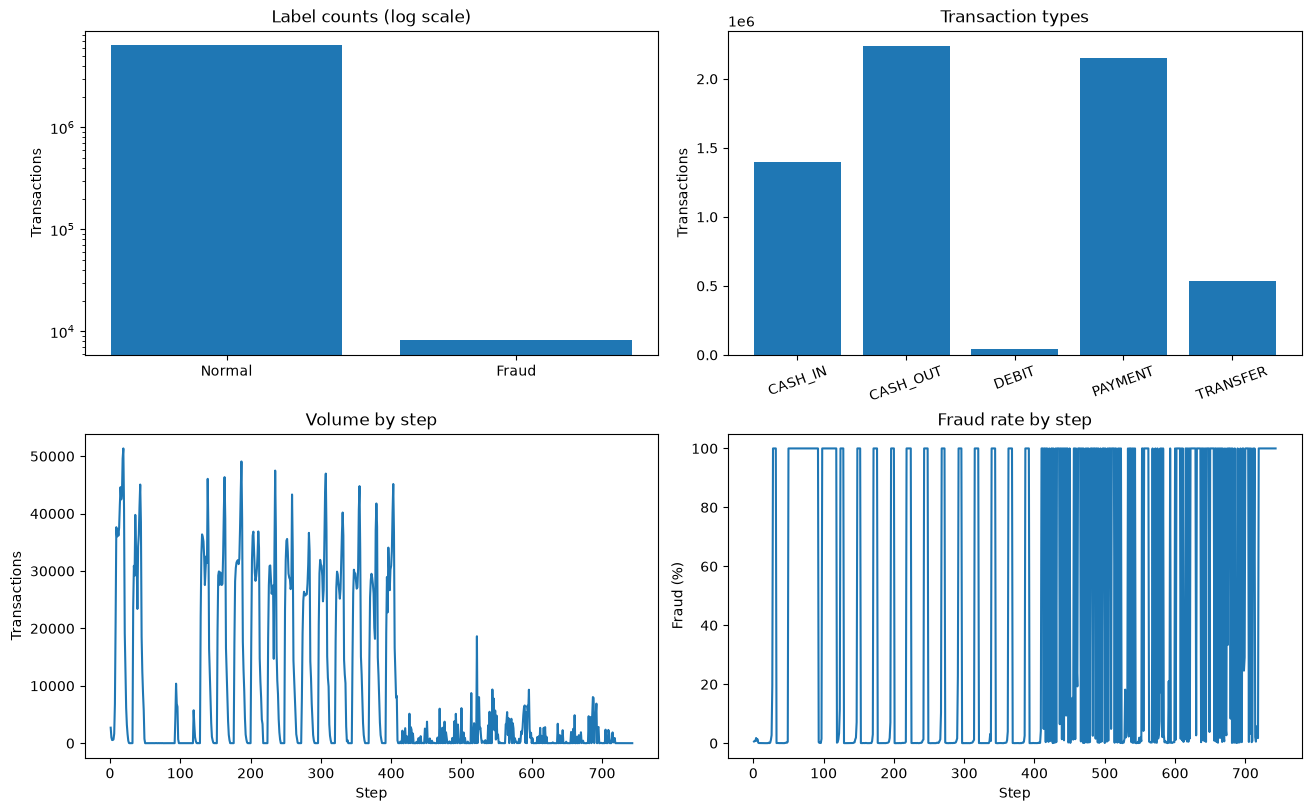

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
axes[0, 0].bar(["Normal", "Fraud"], [overall["normal"], overall["fraud"]])
axes[0, 0].set_yscale("log")
axes[0, 0].set(title="Label counts (log scale)", ylabel="Transactions")
axes[0, 1].bar(by_type["type"], by_type["rows"])
axes[0, 1].tick_params(axis="x", rotation=20)
axes[0, 1].set(title="Transaction types", ylabel="Transactions")
axes[1, 0].plot(by_step["step"], by_step["rows"])
axes[1, 0].set(title="Volume by step", xlabel="Step", ylabel="Transactions")
axes[1, 1].plot(by_step["step"], by_step["fraud_rate"] * 100)
axes[1, 1].set(title="Fraud rate by step", xlabel="Step", ylabel="Fraud (%)")
fig.savefig(REPORT_DIR / "distribution.png", dpi=150)
plt.show()
plt.close(fig)

## Spark 파티션과 실행 계획 확인

CSV의 입력 파티션과 step 집계의 출력 파티션을 비교한다. 파티션별 건수 집계는 Spark executor가 수행하고 작은 결과표만 노트북으로 가져온다. Spark UI에서는 Jobs, Stages, Executors 탭에서 동일한 task 실행을 확인한다.

원본 CSV 입력 파티션: 4
집계 결과 파티션: 1
executor: Spark worker 2개 × 1 core


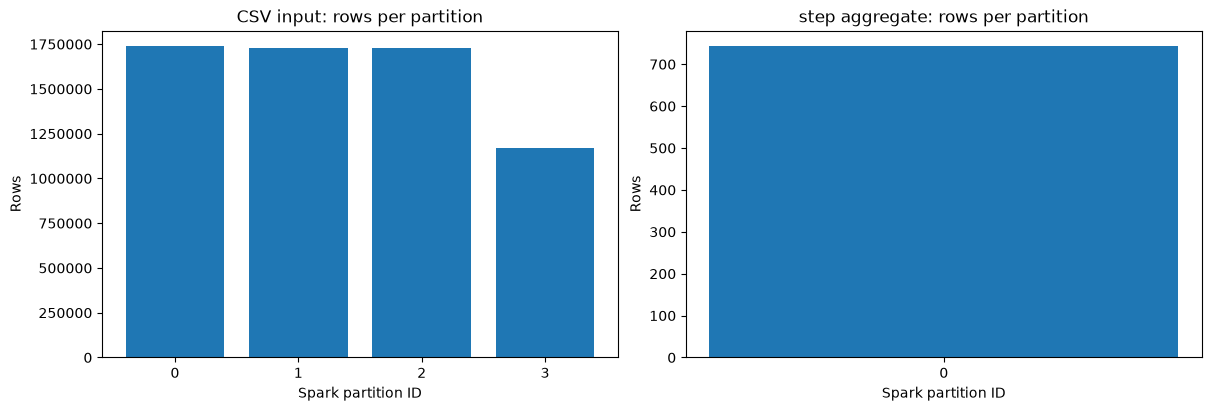

In [6]:
input_partitions = df.rdd.getNumPartitions()
output_partitions = step_aggregate.rdd.getNumPartitions()
input_partition_counts = (
    df.select(F.spark_partition_id().alias("partition_id"))
    .groupBy("partition_id")
    .count()
    .orderBy("partition_id")
    .toPandas()
)
output_partition_counts = (
    step_aggregate.select(F.spark_partition_id().alias("partition_id"))
    .groupBy("partition_id")
    .count()
    .orderBy("partition_id")
    .toPandas()
)
print(f"원본 CSV 입력 파티션: {input_partitions}")
print(f"집계 결과 파티션: {output_partitions}")
print(f"executor: Spark worker {SPARK_WORKERS}개 × {WORKER_CORES} core")
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, (kind, frame) in zip(
    axes, [("CSV input", input_partition_counts), ("step aggregate", output_partition_counts)]
):
    ax.bar(frame["partition_id"].astype(str), frame["count"])
    ax.set(title=f"{kind}: rows per partition", xlabel="Spark partition ID", ylabel="Rows")
    ax.ticklabel_format(axis="y", style="plain")
fig.savefig(REPORT_DIR / "spark_partitions.png", dpi=150)
partition_counts = pd.concat(
    [
        input_partition_counts.assign(kind="CSV input"),
        output_partition_counts.assign(kind="step aggregate"),
    ],
    ignore_index=True,
)
plt.show()
plt.close(fig)
partition_counts.to_csv(REPORT_DIR / "spark_partitions.csv", index=False)
ui_link = (
    f'<a href="{spark.sparkContext.uiWebUrl}" target="_blank" rel="noreferrer">'
    "Spark UI 열기 — Jobs · Stages · Executors</a>"
)
display(HTML(ui_link))

## 4. 시간순 분할 경계 선택

`step`별 누적 건수가 60%, 80%에 가장 가까워지는 경계를 순서대로 선택한다.
동률이면 더 이른 경계를 사용한다. 각 구간에는 최소 하나의 `step`이 있어야 한다.
이는 같은 시간대의 거래를 분리하지 않는 **결정적 근사 분할**이며 정확히 60:20:20일 필요는 없다.
경계 선택 함수에는 사기 레이블을 전달하지 않는다.


In [7]:
def choose_boundaries(step_counts, train_fraction=0.60, validation_fraction=0.20):
    if not (
        0 < train_fraction < 1
        and 0 < validation_fraction < 1
        and train_fraction + validation_fraction < 1
    ):
        raise ValueError("각 분할의 비율은 양수이며 합이 1보다 작아야 한다.")
    counts = step_counts[["step", "rows"]].sort_values("step").reset_index(drop=True)
    if (
        len(counts) < 3
        or counts["step"].duplicated().any()
        or counts.isna().any().any()
        or (counts["rows"] <= 0).any()
    ):
        raise ValueError("3개 이상의 고유 step과 양수 건수가 필요한다.")
    cumulative = counts["rows"].cumsum() / counts["rows"].sum()
    train_index = (cumulative.iloc[:-2] - train_fraction).abs().idxmin()
    val_candidates = cumulative.iloc[train_index + 1 : -1]
    validation_index = (val_candidates - train_fraction - validation_fraction).abs().idxmin()
    return int(counts.loc[train_index, "step"]), int(counts.loc[validation_index, "step"])


# 경계 조건 검증: 균등, 시간 공백, 한 step에 쏠린 분포, 잘못된 입력.
assert choose_boundaries(pd.DataFrame({"step": range(1, 11), "rows": [10] * 10})) == (6, 8)
assert choose_boundaries(pd.DataFrame({"step": [1, 7, 20], "rows": [98, 1, 1]})) == (1, 7)
for invalid in [
    pd.DataFrame({"step": [1, 2], "rows": [1, 1]}),
    pd.DataFrame({"step": [1, 1, 2], "rows": [1, 1, 1]}),
]:
    try:
        choose_boundaries(invalid)
    except ValueError:
        pass
    else:
        raise AssertionError("잘못된 분할 입력을 거부해야 한다.")
train_end, validation_end = choose_boundaries(
    by_step[["step", "rows"]], TRAIN_FRACTION, VALIDATION_FRACTION
)
print(f"Train: step <= {train_end}")
print(f"Validation: {train_end} < step <= {validation_end}")
print(f"Test: step > {validation_end}")

Train: step <= 281
Validation: 281 < step <= 354
Test: step > 354


,split,rows,fraud,min_step,max_step,distinct_steps,normal,row_fraction,fraud_rate
0,train,3820599,3193,1,281,281,3817406,0.600476,0.000836
1,validation,1248498,762,282,354,73,1247736,0.196224,0.000610
2,test,1293523,4258,355,743,389,1289265,0.203300,0.003292


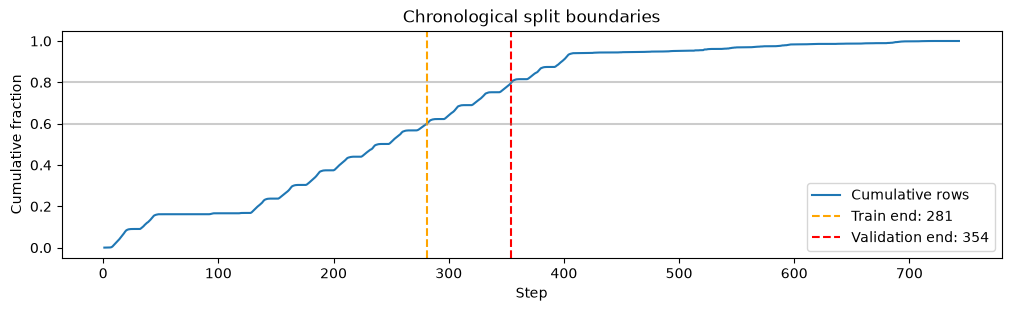

In [8]:
split_df = df.withColumn(
    "split",
    F.when(F.col("step") <= train_end, F.lit("train"))
    .when(F.col("step") <= validation_end, F.lit("validation"))
    .otherwise(F.lit("test")),
)
split_summary = (
    split_df.groupBy("split")
    .agg(
        F.count("*").alias("rows"),
        F.sum("isFraud").alias("fraud"),
        F.min("step").alias("min_step"),
        F.max("step").alias("max_step"),
        F.countDistinct("step").alias("distinct_steps"),
    )
    .toPandas()
    .set_index("split")
    .loc[["train", "validation", "test"]]
    .reset_index()
)
split_summary["normal"] = split_summary["rows"] - split_summary["fraud"]
split_summary["row_fraction"] = split_summary["rows"] / overall["rows"]
split_summary["fraud_rate"] = split_summary["fraud"] / split_summary["rows"]
assert int(split_summary["rows"].sum()) == overall["rows"]
assert int(split_summary["fraud"].sum()) == overall["fraud"]
assert (split_summary["rows"] > 0).all()
assert split_summary.loc[0, "max_step"] < split_summary.loc[1, "min_step"]
assert split_summary.loc[1, "max_step"] < split_summary.loc[2, "min_step"]
assert (
    split_df.groupBy("step").agg(F.countDistinct("split").alias("n")).filter("n != 1").count() == 0
), "동일 step이 여러 구간에 포함된다."
display(split_summary)
if (split_summary["fraud"] == 0).any():
    print("주의: 사기가 없는 구간이 있다. 평가 지표 계산 전에 확인한다.")
split_summary.to_csv(REPORT_DIR / "split_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 3), constrained_layout=True)
ax.plot(by_step["step"], by_step["cumulative_fraction"], label="Cumulative rows")
ax.axvline(train_end, color="orange", linestyle="--", label=f"Train end: {train_end}")
ax.axvline(validation_end, color="red", linestyle="--", label=f"Validation end: {validation_end}")
ax.axhline(0.6, color="gray", alpha=0.4)
ax.axhline(0.8, color="gray", alpha=0.4)
ax.set(xlabel="Step", ylabel="Cumulative fraction", title="Chronological split boundaries")
ax.legend()
fig.savefig(REPORT_DIR / "split_boundaries.png", dpi=150)
plt.show()
plt.close(fig)

## 5. Parquet 저장과 재검증

매번 새로운 실행 ID 경로를 사용해 기존 결과를 덮어쓰지 않는다.
`split=train`, `split=validation`, `split=test` 파티션으로 저장한다.
Parquet 파일 내부나 파일 간의 순서는 보장되지 않으므로 배치 재생 시 `step`을 기준으로
명시적으로 정렬해야 한다. 같은 `step` 내부의 순서를 실제 발생 순서라고 해석하지 않는다.

저장 후 구간별 건수·사기 건수·최소/최대 step을 다시 읽어 비교하고,
전체 행의 다중집합 차집합을 양방향 검사하여 중복 행을 포함한 보존 여부를 확인한다.
검증에 성공한 실행만 `manifest.json`을 만듭니다.


In [9]:
assert not OUTPUT_DIR.exists(), "이미 존재하는 실행 경로이다. 새 실행 ID를 사용한다."
parquet_path = OUTPUT_DIR / "transactions"
write_started = time.perf_counter()
(
    split_df.repartition(8)
    .write.mode("errorifexists")
    .partitionBy("split")
    .parquet(str(parquet_path))
)
restored = spark.read.parquet(str(parquet_path))
restored_summary = (
    restored.groupBy("split")
    .agg(
        F.count("*").alias("rows"),
        F.sum("isFraud").alias("fraud"),
        F.min("step").alias("min_step"),
        F.max("step").alias("max_step"),
        F.countDistinct("step").alias("distinct_steps"),
    )
    .toPandas()
    .sort_values("split")
    .reset_index(drop=True)
)
expected_summary = (
    split_summary[restored_summary.columns].sort_values("split").reset_index(drop=True)
)
pd.testing.assert_frame_equal(restored_summary, expected_summary, check_dtype=False)
assert (
    restored.groupBy("step").agg(F.countDistinct("split").alias("n")).filter("n != 1").count() == 0
)
columns = EXPECTED_COLUMNS + ["split"]
assert split_df.select(columns).exceptAll(restored.select(columns)).limit(1).count() == 0
assert restored.select(columns).exceptAll(split_df.select(columns)).limit(1).count() == 0
write_and_verify_seconds = time.perf_counter() - write_started
print("Parquet 재검증 통과: 행 보존, 레이블 건수, 시간 경계, 동일 step 분리 없음")
print(parquet_path)

Parquet 재검증 통과: 행 보존, 레이블 건수, 시간 경계, 동일 step 분리 없음
/Users/yueun/Desktop/FDS-AI-Agent/data/processed/paysim_time_split/20261117T053742Z-09ddeaeb/transactions


## Spark UI 실행 기록과 executor 작업량

Spark UI REST API에서 완료된 job, stage, worker·executor 통계를 읽는다. executor별 완료 task, 읽은 원본 바이트, shuffle 바이트를 그래프로 저장해 분산 실행이 어떻게 배치됐는지 확인한다. Spark 이벤트 로그도 함께 저장하므로 이 시연은 현재 노트북 프로세스의 local-cluster 결과를 사후에 조회할 수 있다.

,id,hostPort,isActive,totalCores,completedTasks,failedTasks,totalInput,shuffleRead,shuffleWrite
0,0,127.0.0.1:57127,True,1,54,0,2.1 GiB,881.8 MiB,832.6 MiB
1,1,127.0.0.1:57126,True,1,61,0,1.9 GiB,881.6 MiB,930.8 MiB
2,driver,localhost:57117,True,0,0,0,0.0 B,0.0 B,0.0 B


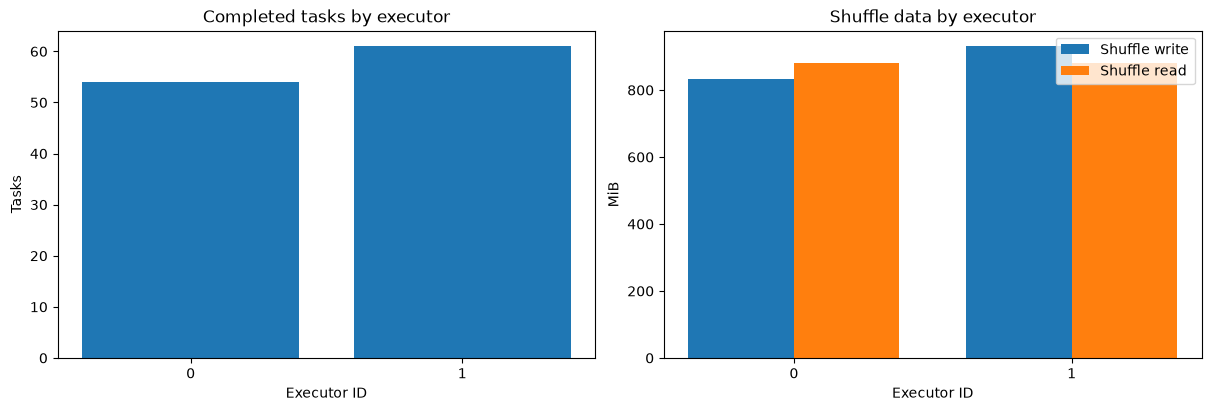

,stageId,attemptId,name,numTasks,duration,inputBytes,shuffleReadBytes,shuffleWriteBytes
44,0,0,first at /var/folders/29/dt4sn0qx31n0l3q59p_8z...,4,None,493731391,0,0
43,1,0,first at /var/folders/29/dt4sn0qx31n0l3q59p_8z...,4,None,265534845,0,264
42,3,0,first at /var/folders/29/dt4sn0qx31n0l3q59p_8z...,1,None,0,264,0
41,4,0,first at /var/folders/29/dt4sn0qx31n0l3q59p_8z...,4,None,265534845,0,36163
40,6,0,first at /var/folders/29/dt4sn0qx31n0l3q59p_8z...,1,None,0,36163,104
39,9,0,first at /var/folders/29/dt4sn0qx31n0l3q59p_8z...,1,None,0,104,0
38,10,0,toPandas at /var/folders/29/dt4sn0qx31n0l3q59p...,4,None,265534845,0,1330
37,12,0,toPandas at /var/folders/29/dt4sn0qx31n0l3q59p...,1,None,0,1330,0
36,14,0,toPandas at /var/folders/29/dt4sn0qx31n0l3q59p...,1,None,0,1330,432
35,17,0,toPandas at /var/folders/29/dt4sn0qx31n0l3q59p...,1,None,0,432,0


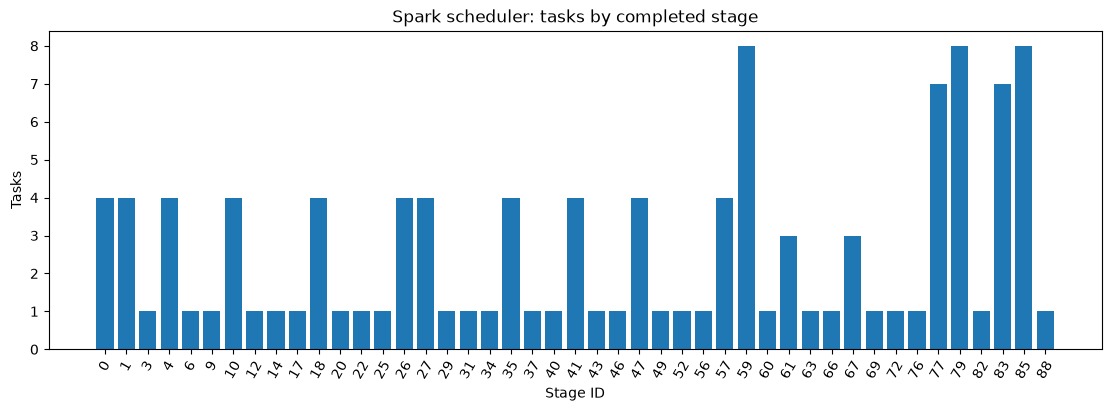

Spark application: app-20261117143743-0000
Completed jobs: 45 | completed stages: 45
Worker executors: 2 | completed tasks: 115
event log: /Users/yueun/Desktop/FDS-AI-Agent/artifacts/reports/20261117T053742Z-09ddeaeb/spark-events


In [10]:
import urllib.request


def read_spark_ui(endpoint):
    url = f"{spark.sparkContext.uiWebUrl}/api/v1/{endpoint}"
    with urllib.request.urlopen(url, timeout=10) as response:
        return json.loads(response.read().decode("utf-8"))


applications = read_spark_ui("applications")
app_id = spark.sparkContext.applicationId
app_path = next((app["id"] for app in applications if app["id"] == app_id), None)
assert app_path is not None, f"Spark UI에서 application을 찾을 수 없다: {app_id}"
api_root = f"applications/{app_path}"
jobs = read_spark_ui(f"{api_root}/jobs?status=succeeded")
stages = read_spark_ui(f"{api_root}/stages?status=complete&withSummaries=true&quantiles=0.5")
executors = read_spark_ui(f"{api_root}/allexecutors")
executor_rows = [
    {
        key: executor.get(key)
        for key in [
            "id",
            "hostPort",
            "isActive",
            "totalCores",
            "completedTasks",
            "failedTasks",
            "totalDuration",
            "totalInputBytes",
            "totalShuffleRead",
            "totalShuffleWrite",
            "maxMemory",
        ]
    }
    for executor in executors
]
executor_summary = pd.DataFrame(executor_rows)
worker_executors = executor_summary[executor_summary["id"].astype(str) != "driver"].copy()
assert not worker_executors.empty, "local-cluster executor가 Spark UI에 나타나지 않는다."
assert worker_executors["completedTasks"].fillna(0).sum() > 0, "executor가 완료한 task가 없다."


def display_bytes(value):
    value = int(value or 0)
    for unit in ["B", "KiB", "MiB", "GiB"]:
        if value < 1024 or unit == "GiB":
            return f"{value:,.1f} {unit}"
        value /= 1024


executor_summary["totalInput"] = executor_summary["totalInputBytes"].map(display_bytes)
executor_summary["shuffleRead"] = executor_summary["totalShuffleRead"].map(display_bytes)
executor_summary["shuffleWrite"] = executor_summary["totalShuffleWrite"].map(display_bytes)
display(
    executor_summary[
        [
            "id",
            "hostPort",
            "isActive",
            "totalCores",
            "completedTasks",
            "failedTasks",
            "totalInput",
            "shuffleRead",
            "shuffleWrite",
        ]
    ]
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].bar(worker_executors["id"].astype(str), worker_executors["completedTasks"])
axes[0].set(title="Completed tasks by executor", xlabel="Executor ID", ylabel="Tasks")
executor_positions = range(len(worker_executors))
bar_width = 0.38
axes[1].bar(
    [position - bar_width / 2 for position in executor_positions],
    worker_executors["totalShuffleWrite"] / 1024**2,
    width=bar_width,
    label="Shuffle write",
)
axes[1].bar(
    [position + bar_width / 2 for position in executor_positions],
    worker_executors["totalShuffleRead"] / 1024**2,
    width=bar_width,
    label="Shuffle read",
)
axes[1].set_xticks(list(executor_positions), worker_executors["id"].astype(str))
axes[1].set(title="Shuffle data by executor", xlabel="Executor ID", ylabel="MiB")
axes[1].legend()
fig.savefig(REPORT_DIR / "spark_executors.png", dpi=150)
plt.show()
plt.close(fig)

stage_rows = [
    {
        "stageId": s.get("stageId"),
        "attemptId": s.get("attemptId"),
        "name": s.get("name"),
        "numTasks": s.get("numTasks"),
        "duration": s.get("duration"),
        "inputBytes": s.get("inputBytes"),
        "shuffleReadBytes": s.get("shuffleReadBytes"),
        "shuffleWriteBytes": s.get("shuffleWriteBytes"),
    }
    for s in stages
]
stage_summary = pd.DataFrame(stage_rows).sort_values("stageId")
display(stage_summary.head(20))
if not stage_summary.empty:
    fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
    ax.bar(stage_summary["stageId"].astype(str), stage_summary["numTasks"])
    ax.set(title="Spark scheduler: tasks by completed stage", xlabel="Stage ID", ylabel="Tasks")
    ax.tick_params(axis="x", rotation=60)
    fig.savefig(REPORT_DIR / "spark_stages.png", dpi=150)
    plt.show()
    plt.close(fig)
executor_summary.to_csv(REPORT_DIR / "spark_executors.csv", index=False)
stage_summary.to_csv(REPORT_DIR / "spark_stages.csv", index=False)
spark_metrics = {
    "application_id": app_id,
    "master": spark.sparkContext.master,
    "ui_url": spark.sparkContext.uiWebUrl,
    "jobs": jobs,
    "stages": stages,
    "executors": executor_rows,
    "worker_count": SPARK_WORKERS,
    "worker_cores_each": WORKER_CORES,
    "event_log_dir": (REPORT_DIR / "spark-events").as_uri(),
}
(REPORT_DIR / "spark_ui_metrics.json").write_text(
    json.dumps(spark_metrics, ensure_ascii=False, indent=2, default=str), encoding="utf-8"
)
print(f"Spark application: {app_id}")
print(f"Completed jobs: {len(jobs)} | completed stages: {len(stages)}")
completed_tasks = int(worker_executors["completedTasks"].sum())
print(f"Worker executors: {len(worker_executors)} | completed tasks: {completed_tasks:,}")
print(f"event log: {REPORT_DIR / 'spark-events'}")

In [11]:
manifest = {
    "run_id": RUN_ID,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "source": source_info,
    "versions": {
        "python": platform.python_version(),
        "spark": spark.version,
        "spark_master": spark.sparkContext.master,
        "pandas": pd.__version__,
    },
    "quality": quality,
    "overall": overall,
    "split_policy": {
        "method": "nearest_cumulative_row_fraction_by_step_sequential",
        "target_fractions": {
            "train": TRAIN_FRACTION,
            "validation": VALIDATION_FRACTION,
            "test": 1 - TRAIN_FRACTION - VALIDATION_FRACTION,
        },
        "train_end_step": train_end,
        "validation_end_step": validation_end,
        "boundary_uses_labels": False,
        "same_step_crosses_splits": False,
        "history_rule": "history.step < current.step",
    },
    "splits": json.loads(split_summary.to_json(orient="records")),
    "parquet_path": str(parquet_path.relative_to(ROOT)),
    "report_path": str(REPORT_DIR.relative_to(ROOT)),
    "contains_labels": True,
    "verified": True,
    "verification": "aggregate equality + bidirectional exceptAll including duplicates",
    "elapsed_seconds": round(time.perf_counter() - started, 2),
    "write_and_verify_seconds": round(write_and_verify_seconds, 2),
    "spark_jobs": len(jobs),
    "spark_stages": len(stages),
    "spark_worker_executors": len(worker_executors),
    "spark_completed_executor_tasks": int(worker_executors["completedTasks"].sum()),
    "spark_ui_metrics": str((REPORT_DIR / "spark_ui_metrics.json").relative_to(ROOT)),
}
manifest_text = json.dumps(manifest, ensure_ascii=False, indent=2)
(OUTPUT_DIR / "manifest.json").write_text(manifest_text, encoding="utf-8")
(REPORT_DIR / "manifest.json").write_text(manifest_text, encoding="utf-8")
print(
    f"전체 {overall['rows']:,}건 / 사기 {overall['fraud']:,}건"
    f" / 사기 비율 {overall['fraud_rate']:.4%}"
)
print("결과 manifest:", OUTPUT_DIR / "manifest.json")
print("집계표와 그래프:", REPORT_DIR)
print("총 소요 시간(초):", manifest["elapsed_seconds"])
df.unpersist()
spark.stop()

전체 6,362,620건 / 사기 8,213건 / 사기 비율 0.1291%
결과 manifest: /Users/yueun/Desktop/FDS-AI-Agent/data/processed/paysim_time_split/20261117T053742Z-09ddeaeb/manifest.json
집계표와 그래프: /Users/yueun/Desktop/FDS-AI-Agent/artifacts/reports/20261117T053742Z-09ddeaeb
총 소요 시간(초): 73.24


## 다음 작업

1. 거래 시점에 이용 가능한 컬럼만 선택하고, 과거 `step`만 사용하는 특징 생성 노트북을 작성한다.
2. Train으로 LightGBM을 학습하고 Validation으로 모델·임계값을 결정한다.
3. 고정된 모델을 Test로 최종 평가한 뒤, 정답을 분리한 배치 재생 데이터를 만듭니다.

`isFraud`, `isFlaggedFraud`, 거래 이후 잔액은 초기 모델 특징에서 제외한다.
계좌 ID는 이력 조회에 사용하며, Agent에는 정답이 포함된 연구용 Parquet을 직접 넘기지 않는다.

참고: [PySpark 4.0.1 설치](https://spark.apache.org/docs/4.0.1/api/python/getting_started/install.html),
[노트북 실행과 출력 저장](https://nbclient.readthedocs.io/en/latest/client.html)
